In [7]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import torch
from torch.utils.data import DataLoader
import numpy as np
import wandb
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, roc_auc_score
from src.data import PROCESSED
from src.eval import PREDS_DIR, ROOT, WANDB_ENTITY, WANDB_PROJECT, evaluate_and_log
from src.dl_dataset import load_cache, ApneaDataset
from src.train_dl import CKPT_DIR, run_cv_experiment, predict_loader
from src.dl_models import ApneaSeqNet

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

folds_df = pd.read_csv(PROCESSED / "folds.csv")
train_cache = load_cache(folds_df["record"].unique())

GPU: NVIDIA RTX A2000 8GB Laptop GPU


load_cache:   0%|          | 0/35 [00:00<?, ?npz/s]

In [ ]:
# Main Model — RR + EDR (3-min context) on strict patient-wise CV
oof_main, m_main = run_cv_experiment(
    mode="rr_edr", context_mins=3, lr=3e-3, split_col="patient_fold",
    run_name="cnn_bigru_rredr_3m", cache=train_cache, use_wandb=True
)

In [ ]:
# Ablations on the exact same patient_fold split
oof_1m, m_1m = run_cv_experiment(mode="rr_edr", context_mins=1, lr=3e-3, split_col="patient_fold", run_name="cnn_bigru_rredr_1m", cache=train_cache)
oof_rr, m_rr = run_cv_experiment(mode="rr", context_mins=3, lr=3e-3, split_col="patient_fold", run_name="cnn_bigru_rr_3m",cache=train_cache)
oof_raw, m_raw = run_cv_experiment(mode="raw_ecg", context_mins=1, lr=3e-3, split_col="patient_fold", run_name="cnn_bigru_rawecg", cache=train_cache)

In [ ]:
# Leakage Audit — random minute-level CV vs patient-wise CV
_, m_main_rand = run_cv_experiment(mode="rr_edr", context_mins=1, lr=3e-3, split_col="random_fold", run_name="cnn_bigru_rredr_1m", cache=train_cache)
_, m_raw_rand = run_cv_experiment(mode="raw_ecg", context_mins=1, lr=3e-3, split_col="random_fold", run_name="cnn_bigru_rawecg", cache=train_cache)

In [2]:
folds_df = pd.read_csv(PROCESSED / "folds.csv")
p_main = pd.read_csv(PREDS_DIR / "patient_fold_cnn_bigru_rredr_3m.csv")
p_raw  = pd.read_csv(PREDS_DIR / "patient_fold_cnn_bigru_rawecg.csv")

def per_patient_summary(pred_df, folds_df):
    df = pred_df.merge(folds_df[["record", "minute", "patient_fold", "group"]], on=["record", "minute"])
    rows = []
    for rec, g in df.groupby("record"):
        y, pr, yp = g["label"].to_numpy(), g["y_prob"].to_numpy(), g["y_pred"].to_numpy()
        auc = roc_auc_score(y, pr) if len(np.unique(y)) == 2 else np.nan
        true_f, pred_f = y.mean(), yp.mean()
        rows.append({
            "record": rec, "fold": g["patient_fold"].iloc[0], "group": g["group"].iloc[0],
            "n_min": len(g), "acc": accuracy_score(y, yp), "auc": auc,
            "true_frac": true_f, "pred_frac": pred_f, "abs_err": abs(true_f - pred_f),
            "screen_ok": (true_f >= 5/60) == (pred_f >= 5/60),
        })
    return pd.DataFrame(rows).sort_values("acc")

s_main = per_patient_summary(p_main, folds_df)
s_raw  = per_patient_summary(p_raw, folds_df)

print("=== rredr_3m: Screen Misses ===")
display(s_main[~s_main["screen_ok"]])

print("=== rredr_3m: 7 Worst Patients by Accuracy ===")
display(s_main.head(7).round(3))

print("=== Fold 0 Breakdown: Raw ECG vs RR+EDR 3m ===")
f0 = s_raw[s_raw["fold"] == 0][["record", "group", "acc", "auc", "true_frac", "pred_frac"]].merge(
    s_main[s_main["fold"] == 0][["record", "acc", "auc", "pred_frac"]],
    on="record", suffixes=("_raw", "_rredr3m")
)
# Check raw ECG R-peak polarity (negative skew/min > max flags inverted lead)
f0["ecg_skew"] = [float(pd.Series(train_cache[r]["raw_ecg"][0]).skew()) for r in f0["record"]]
display(f0.sort_values("acc_raw").round(3))

=== rredr_3m: Screen Misses (1/35) ===


,record,fold,group,n_min,acc,auc,true_frac,pred_frac,abs_err,screen_ok
9,a10,1,a,517,0.831721,0.875372,0.193424,0.079304,0.11412,False


=== rredr_3m: 7 Worst Patients by Accuracy ===


,record,fold,group,n_min,acc,auc,true_frac,pred_frac,abs_err,screen_ok
10,a11,0,a,466,0.721,0.778,0.476,0.361,0.116,True
22,b03,4,b,441,0.764,0.968,0.166,0.388,0.222,True
5,a06,3,a,510,0.800,0.885,0.404,0.267,0.137,True
7,a08,0,a,501,0.820,0.932,0.377,0.493,0.116,True
16,a17,4,a,483,0.822,0.860,0.323,0.203,0.120,True
6,a07,1,a,506,0.828,0.933,0.636,0.796,0.160,True
4,a05,4,a,454,0.828,0.951,0.608,0.767,0.159,True


=== Fold 0 Breakdown: Raw ECG vs RR+EDR 3m ===


,record,group,acc_raw,auc_raw,true_frac,pred_frac_raw,acc_rredr3m,auc_rredr3m,pred_frac_rredr3m,ecg_skew
0,a12,a,0.104,0.555,0.925,0.029,0.842,0.918,0.789,-4.154
1,c03,c,0.502,NaN,0.000,0.498,0.998,NaN,0.002,4.230
2,a11,a,0.674,0.798,0.476,0.193,0.721,0.778,0.361,2.290
3,a08,a,0.802,0.872,0.377,0.415,0.820,0.932,0.493,4.111
4,a16,a,0.838,0.918,0.667,0.608,0.898,0.951,0.594,4.295
5,b05,b,0.856,0.552,0.144,0.000,0.884,0.922,0.088,-0.382
6,c01,c,0.951,NaN,0.000,0.049,1.000,NaN,0.000,3.593


In [2]:
from src.dl_dataset import load_cache
from src.train_dl import eval_heldout_test

test_df = pd.read_csv(PROCESSED / "test_clean.csv")
test_cache = load_cache(test_df["record"].unique())

runs = [
    ("rr_edr",  3, "cnn_bigru_rredr_3m"),
    ("rr_edr",  1, "cnn_bigru_rredr_1m"),
    ("rr",      3, "cnn_bigru_rr_3m"),
    ("raw_ecg", 1, "cnn_bigru_rawecg"),
]

test_results = {}
for mode, ctx, name in runs:
    test_results[name] = eval_heldout_test(
        mode=mode, context_mins=ctx, run_name=name,
        use_wandb=True, wandb_project=WANDB_PROJECT, cache=test_cache
    )

test_table = pd.DataFrame(test_results).T.round(4)
display(test_table)

load_cache:   0%|          | 0/35 [00:00<?, ?npz/s]

Fetched OOF threshold for cnn_bigru_rredr_3m from W&B: 0.4750


test f0:   0%|          | 0/65 [00:00<?, ?bt/s]

test f1:   0%|          | 0/65 [00:00<?, ?bt/s]

test f2:   0%|          | 0/65 [00:00<?, ?bt/s]

test f3:   0%|          | 0/65 [00:00<?, ?bt/s]

... (22 outputs left out)

test f4:   0%|          | 0/65 [00:00<?, ?bt/s]

accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.86969
f1,0.82903
patient_frac_mae,0.08731


  wandb -> https://forge.coreweave.com/wandb/emammadli/apnea-ecg-ml/runs/a2hoyfh0
[test | cnn_bigru_rawecg] Acc=0.8697 Sens=0.8023 Spec=0.9134 F1=0.8290 AUC=0.9361 (thr=0.62, PatAcc=0.886)


,threshold,accuracy,sensitivity,specificity,f1,roc_auc,patient_frac_mae,patient_screen_acc
cnn_bigru_rredr_3m,0.475,0.9108,0.9040,0.9151,0.8886,0.9694,0.0518,1.0000
cnn_bigru_rredr_1m,0.445,0.8567,0.8755,0.8445,0.8279,0.9361,0.0909,0.9143
cnn_bigru_rr_3m,0.570,0.8913,0.8345,0.9281,0.8580,0.9466,0.0699,1.0000
cnn_bigru_rawecg,0.620,0.8697,0.8023,0.9134,0.8290,0.9361,0.0873,0.8857


In [8]:
for mode, ctx, name, thr in [
    ("raw_ecg", 1, "cnn_bigru_rawecg",   0.630),
    ("rr_edr",  1, "cnn_bigru_rredr_1m", 0.645),
]:
    ds = ApneaDataset(test_df, test_cache, mode=mode, context_mins=ctx, augment=False)
    loader = DataLoader(ds, batch_size=256, shuffle=False, pin_memory=(device.type == "cuda"))

    preds = []
    for f in range(5):
        m = ApneaSeqNet(mode=mode).to(device)
        m.load_state_dict(torch.load(CKPT_DIR / f"{name}_random_fold_f{f}.pt", map_location=device, weights_only=True))
        preds.append(predict_loader(m, loader, device))

    evaluate_and_log(
        test_df, np.mean(preds, axis=0),
        model_name=name, split_type="test_from_random",
        threshold=thr, config={"mode": mode, "context_mins": ctx, "trained_on": "random_fold"},
        use_wandb=True,
    )

accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.86746
f1,0.82394
patient_frac_mae,0.0909


  wandb -> https://forge.coreweave.com/wandb/emammadli/apnea-ecg-ml/runs/uo7axkuy
[test_from_random | cnn_bigru_rawecg] Acc=0.8675 Sens=0.7876 Spec=0.9193 F1=0.8239 AUC=0.9370 (thr=0.63, PatAcc=0.886)


accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.87066
f1,0.82872
patient_frac_mae,0.07416


  wandb -> https://forge.coreweave.com/wandb/emammadli/apnea-ecg-ml/runs/n9iq6qse
[test_from_random | cnn_bigru_rredr_1m] Acc=0.8707 Sens=0.7947 Spec=0.9200 F1=0.8287 AUC=0.9380 (thr=0.65, PatAcc=1.000)


In [15]:
METRICS = [
    "accuracy", "sensitivity", "specificity", "f1",
    "roc_auc", "patient_frac_mae", "patient_screen_acc", "threshold"
]

SPLIT_SUFFIXES = ("test_from_random", "patient_fold", "random_fold", "test")

def _parse_run_name(name: str):
    for sp in SPLIT_SUFFIXES:
        if name.endswith(f"_{sp}"):
            return name[: -(len(sp) + 1)], sp
    return None, None

def _extract_metrics(run) -> dict:
    # Prefer summary; fall back to last logged history row if summary is empty/lagging
    src = dict(run.summary)
    if "roc_auc" not in src:
        hist = run.history(keys=METRICS)
        if not hist.empty:
            src = hist.iloc[-1].to_dict()
    return {k: src.get(k, np.nan) for k in METRICS}

def fetch_wandb_summary(project: str = WANDB_PROJECT, entity: str | None = WANDB_ENTITY) -> pd.DataFrame:
    api = wandb.Api()
    path = f"{entity}/{project}" if entity else project
    latest = {}

    for run in sorted(api.runs(path), key=lambda r: r.created_at):
        if run.state != "finished":
            continue
        model = run.config.get("model")
        split = run.config.get("split_type")
        if not model or not split:
            model, split = _parse_run_name(run.name)
        if not model or not split:
            continue

        vals = _extract_metrics(run)
        if pd.isna(vals["roc_auc"]) or pd.isna(vals["f1"]):
            continue

        latest[(model, split)] = {
            "model": model,
            "split_type": split,
            "run_name": run.name,
            **vals,
        }

    return pd.DataFrame(latest.values()).sort_values(["split_type", "model"]).reset_index(drop=True)

wb_df = fetch_wandb_summary()
display(wb_df[["model", "split_type", "f1", "roc_auc", "sensitivity", "specificity", "patient_screen_acc"]].round(4))


,model,split_type,f1,roc_auc,sensitivity,specificity,patient_screen_acc
0,cnn_bigru_rawecg,patient_fold,0.7371,0.8445,0.7119,0.8573,0.7429
1,cnn_bigru_rr_3m,patient_fold,0.8418,0.9370,0.8326,0.9054,0.9143
2,cnn_bigru_rredr_1m,patient_fold,0.8287,0.9310,0.8453,0.8735,0.8857
3,cnn_bigru_rredr_3m,patient_fold,0.8751,0.9562,0.8757,0.9184,0.9714
4,cnn_bigru_rawecg,random_fold,0.9054,0.9781,0.8980,0.9443,0.9714
5,cnn_bigru_rredr_1m,random_fold,0.8926,0.9719,0.8899,0.9324,1.0000
6,cnn_bigru_rawecg,test,0.8290,0.9361,0.8023,0.9134,0.8857
7,cnn_bigru_rr_3m,test,0.8580,0.9466,0.8345,0.9281,1.0000
8,cnn_bigru_rredr_1m,test,0.8279,0.9361,0.8755,0.8445,0.9143
9,cnn_bigru_rredr_3m,test,0.8886,0.9694,0.9040,0.9151,1.0000


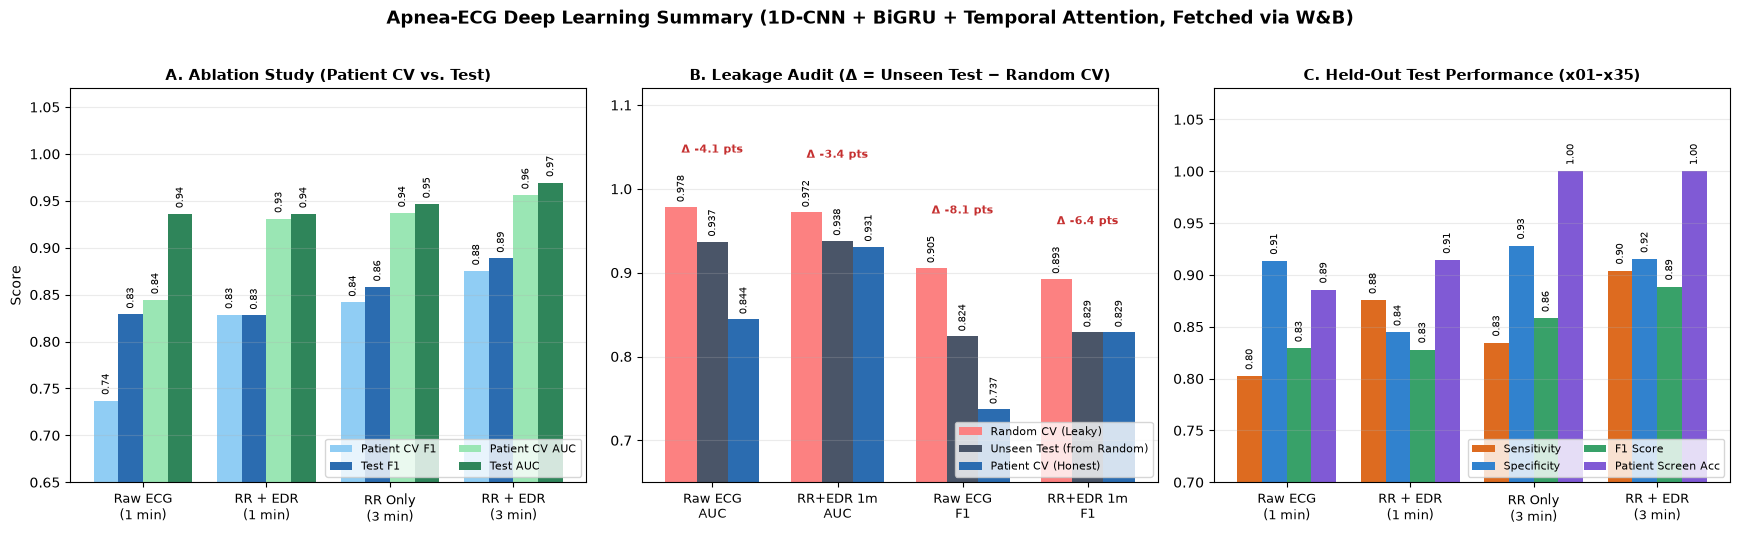

In [17]:
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = [
    ("cnn_bigru_rawecg",   "Raw ECG\n(1 min)"),
    ("cnn_bigru_rredr_1m", "RR + EDR\n(1 min)"),
    ("cnn_bigru_rr_3m",    "RR Only\n(3 min)"),
    ("cnn_bigru_rredr_3m", "RR + EDR\n(3 min)"),
]

def get_val(df, model, split, metric):
    sub = df[(df["model"] == model) & (df["split_type"] == split)]
    return float(sub[metric].iloc[0]) if len(sub) else np.nan

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2))

# ------------------------------------------------------------------
# Panel A: Ablation Ladder — Patient CV vs Held-Out Test (F1 & AUC)
# ------------------------------------------------------------------
ax = axes[0]
x = np.arange(len(MODEL_ORDER))
w = 0.20
labels = [lbl for _, lbl in MODEL_ORDER]

cv_f1   = [get_val(wb_df, m, "patient_fold", "f1")      for m, _ in MODEL_ORDER]
te_f1   = [get_val(wb_df, m, "test",         "f1")      for m, _ in MODEL_ORDER]
cv_auc  = [get_val(wb_df, m, "patient_fold", "roc_auc") for m, _ in MODEL_ORDER]
te_auc  = [get_val(wb_df, m, "test",         "roc_auc") for m, _ in MODEL_ORDER]

bars = [
    ax.bar(x - 1.5*w, cv_f1,  w, label="Patient CV F1",  color="#90cdf4"),
    ax.bar(x - 0.5*w, te_f1,  w, label="Test F1",        color="#2b6cb0"),
    ax.bar(x + 0.5*w, cv_auc, w, label="Patient CV AUC", color="#9ae6b4"),
    ax.bar(x + 1.5*w, te_auc, w, label="Test AUC",       color="#2f855a"),
]
for group in bars:
    for b in group:
        v = b.get_height()
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width()/2, v + 0.006, f"{v:.2f}",
                    ha="center", va="bottom", fontsize=7.5, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0.65, 1.07)
ax.set_ylabel("Score")
ax.set_title("A. Ablation Study (Patient CV vs. Test)", fontsize=11, fontweight="bold")
ax.legend(ncol=2, fontsize=8, loc="lower right", frameon=True)
ax.grid(axis="y", alpha=0.25)

# ------------------------------------------------------------------
# Panel B: Leakage Audit — Random CV vs. Unseen Test vs. Patient CV
# ------------------------------------------------------------------
ax = axes[1]
leak_items = [
    ("cnn_bigru_rawecg",   "roc_auc", "Raw ECG\nAUC"),
    ("cnn_bigru_rredr_1m", "roc_auc", "RR+EDR 1m\nAUC"),
    ("cnn_bigru_rawecg",   "f1",      "Raw ECG\nF1"),
    ("cnn_bigru_rredr_1m", "f1",      "RR+EDR 1m\nF1"),
]
xl = np.arange(len(leak_items))
wl = 0.25

rand_vals = [get_val(wb_df, m, "random_fold",      met) for m, met, _ in leak_items]
tfr_vals  = [get_val(wb_df, m, "test_from_random", met) for m, met, _ in leak_items]
pat_vals  = [get_val(wb_df, m, "patient_fold",     met) for m, met, _ in leak_items]

leak_bars = [
    ax.bar(xl - wl, rand_vals, wl, label="Random CV (Leaky)",         color="#fc8181"),
    ax.bar(xl,      tfr_vals,  wl, label="Unseen Test (from Random)", color="#4a5568"),
    ax.bar(xl + wl, pat_vals,  wl, label="Patient CV (Honest)",       color="#2b6cb0"),
]

for group in leak_bars:
    for b in group:
        v = b.get_height()
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width()/2, v + 0.006, f"{v:.3f}",
                    ha="center", va="bottom", fontsize=7.5, rotation=90)

# Annotate Optimism Drop: how far Random CV's promise fell on unseen test patients
for i, (rv, tv, pv) in enumerate(zip(rand_vals, tfr_vals, pat_vals)):
    if not (np.isnan(rv) or np.isnan(tv)):
        drop = (tv - rv) * 100
        top = np.nanmax([rv, tv, pv])
        ax.text(xl[i], top + 0.062, f"Δ {drop:+.1f} pts", ha="center", va="bottom",
                fontsize=8.2, fontweight="bold", color="#c53030")

ax.set_xticks(xl)
ax.set_xticklabels([lbl for _, _, lbl in leak_items], fontsize=9)
ax.set_ylim(0.65, 1.12)
ax.set_title("B. Leakage Audit (Δ = Unseen Test − Random CV)", fontsize=10.5, fontweight="bold")
ax.legend(fontsize=8, loc="lower right", frameon=True)
ax.grid(axis="y", alpha=0.25)

# ------------------------------------------------------------------
# Panel C: Held-Out Test (x01–x35) Clinical Screening Profile
# ------------------------------------------------------------------
ax = axes[2]
clin_metrics = [
    ("sensitivity",        "Sensitivity",        "#dd6b20"),
    ("specificity",        "Specificity",        "#3182ce"),
    ("f1",                 "F1 Score",           "#38a169"),
    ("patient_screen_acc", "Patient Screen Acc", "#805ad5"),
]
for idx, (met, lbl, col) in enumerate(clin_metrics):
    vals = [get_val(wb_df, m, "test", met) for m, _ in MODEL_ORDER]
    offset = (idx - 1.5) * w
    grp = ax.bar(x + offset, vals, w, label=lbl, color=col)
    for b in grp:
        v = b.get_height()
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width()/2, v + 0.006, f"{v:.2f}",
                    ha="center", va="bottom", fontsize=7.5, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0.70, 1.08)
ax.set_title("C. Held-Out Test Performance (x01–x35)", fontsize=11, fontweight="bold")
ax.legend(ncol=2, fontsize=8, loc="lower right", frameon=True)
ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Apnea-ECG Deep Learning Summary (1D-CNN + BiGRU + Temporal Attention, Fetched via W&B)",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(FIG / "fig_dl_summary.png", dpi=200, bbox_inches="tight")
plt.show()